In [1]:
# Importa il modulo os per interagire con il sistema operativo e gestire i percorsi dei file
import os
# Acquisisce il percorso della cartella di lavoro corrente e lo salva nella variabile HOME
HOME = os.getcwd()

from google.colab import drive

In [2]:
# Importa numpy per la gestione efficiente di vettori, matrici e calcoli matematici
import numpy as np
!pip install opencv-python
# Importa cv2 (OpenCV) per elaborare e manipolare immagini e flussi video
import cv2
# Importa il sottomodulo pyplot per tracciare e visualizzare grafici statistici
import matplotlib.pyplot as plt
# Importa la classe Image dal pacchetto PIL per aprire e salvare immagini in vari formati
from PIL import Image

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 73.8/73.8 MB 69.5 MB/s  0:00:01


In [3]:
# Installa la libreria natsort per l'ordinamento naturale delle stringhe (es. 'video_2' prima di 'video_10')
!pip install natsort
# Importa la funzione natsorted per ordinare le liste in modo naturale
from natsort import natsorted
# Installa ultralytics, pacchetto ufficiale per l'utilizzo del modello YOLOv8
!pip install ultralytics
# Importa il pacchetto ultralytics per l'object detection
import ultralytics
# Verifica i requisiti di sistema e la disponibilità di accelerazione hardware (GPU)
ultralytics.checks()

Ultralytics 8.4.212 🚀 Python-3.13.18 torch-2.14.1+cpu CPU (AMD EPYC 7B13)
Setup complete ✅ (24 CPUs, 47.0 GB RAM, 0.6/225.3 GB disk)


In [4]:
# Importa la classe YOLO per caricare ed eseguire il modello di Object Detection
from ultralytics import YOLO
# Importa il modulo drive per connettere Google Drive a Colab
from google.colab import drive

# Lista contenente i nomi dei file dei pesi preallenati salvati
weigth_list = [
    "pretrained-weights-2026-11-02_12-59-52.pt"
]
# Variabile per abilitare o disabilitare il comportamento degli oggetti speciali
special = "special"
# Sposta l'esecuzione del terminale nella cartella HOME
!cd {HOME}

# Estrae il nome del file dei pesi escludendo l'estensione '.pt'
weigth_filename = weigth_list[0].split('.')[0]

# Definisce la dimensione delle immagini in pixel (larghezza)
TRAINING_WIDTH = 640
# Definisce la dimensione delle immagini in pixel (altezza)
TRAINING_HEIGHT = 640

# Monta lo storage personale di Google Drive nella cartella /content/gdrive
drive.mount('/content/gdrive')
# Copia il file dei pesi dal proprio Google Drive locale alla directory corrente di Colab
!cp /content/gdrive/MyDrive/tesi/{weigth_filename}.pt {HOME}

# Inizializza il modello YOLO con i pesi copiati pronti per l'inferenza
model = YOLO(f'{weigth_filename}.pt')

Mounted at /content/gdrive


In [5]:
# Stampa a schermo il nome del file di pesi attualmente in uso per verificarne la correttezza
print(weigth_filename)

pretrained-weights-2026-11-02_12-59-52


In [6]:
# Definisce la dimensione fissa della finestra temporale dei frame da analizzare
window_size = 3

In [7]:
# X, oggetti che possono apparire in un frame (driver-window, driver-seat-belt, passenger-window, passenger-seat-belt, passenger-sun-visor, driver-sun-visor, passenger-grab-handle)
X = model.names
print(X)

{0: 'driver-seat-belt', 1: 'driver-sun-visor', 2: 'driver-window', 3: 'passenger-grab-handle', 4: 'passenger-seat-belt', 5: 'passenger-sun-visor', 6: 'passenger-window'}


In [8]:
# Ritorna la classe dell'oggetto speciale se presente (per classificarlo senza utilizzare alcuna euristica), altrimenti None
# questa funzione è utile per evitare di classificare il frame con un euristica sapendo che un determinato oggetto è caratterizzante di una classe (e.g. passenger-grab-handle)
def has_special_object(X, results, conf_treshold = 0.7, special_objects_names = []):
  # Se l'analisi degli oggetti speciali è disattivata, ritorna immediatamente None
  if special == "nospecial":
    # Ritorna None
    return None
  # Inizializza l'indice per scorrere i risultati
  index = 0
  # Itera su ciascun risultato di rilevamento
  for r in results:
    # Itera sugli indici delle bounding box rilevate
    for index in range(0, len(r.boxes.cls)):
      # Itera sulla lista dei nomi degli oggetti speciali da cercare
      for special_object in special_objects_names:
        # Controlla se l'oggetto speciale corrisponde al nome della classe corrente con confidenza superiore alla soglia
        if special_object in X[int(r.boxes.cls[index])] and float(r.boxes.conf[index]) > conf_treshold:
          # Se l'oggetto appartiene alla classe passeggero, ritorna la stringa passenger
          if "passenger" in special_object:
            # Ritorna passenger
            return "passenger"
          # Altrimenti, se l'oggetto appartiene alla classe conducente, ritorna driver
          elif "driver" in special_object:
            # Ritorna driver
            return "driver"
  # Se nessun oggetto speciale soddisfa i criteri, ritorna None
  return None

In [9]:
# Imposta la soglia di confidenza minima richiesta per convalidare il rilevamento di oggetti speciali
SPECIAL_OBJ_TRESHOLD = 0.8

In [10]:
# Definizione della funzione baseline che classifica il frame contando semplicemente la cardinalità delle bounding box rilevate
def baseline(results, special_objects_names):
  # Numero di bounding box di oggetti della classe driver riconosciuti nel frame corrente dal modello
  driver_class_bb_cardinality = 0
  # Numero di bounding box di oggetti della classe passenger riconosciuti nel frame corrente dal modello
  passenger_class_bb_cardinality = 0

  # Iteriamo sui risultati restituiti dal modello YOLO per analizzare le classi dei box predetti
  for r in results:
    for c in r.boxes.cls:
      # si noti che basta controllare se la classe è contenuta come sottostringa (e.g. driver-window, driver-seat-belt, driver-handle, etc),
      if "driver" in X[int(c)]:
        driver_class_bb_cardinality += 1
      elif "passenger" in X[int(c)]:
        passenger_class_bb_cardinality += 1
  # classifichiamo il frame confrontando le due cardinalità calcolate
  if driver_class_bb_cardinality > passenger_class_bb_cardinality:
    return "driver"
  elif passenger_class_bb_cardinality > driver_class_bb_cardinality:
    return "passenger"
  else:
    return "none"

In [11]:
# Calcola la somma dei valori di confidenza per le classi driver e passenger
def compute_sum_confidence(X_k, results):
  # Inizializza la somma della confidenza per la classe driver
  driver_bb_conf = 0
  # Inizializza la somma della confidenza per la classe passenger
  passenger_bb_conf = 0

  # Inizializza l'indice per tracciare le corrispondenze
  index = 0
  # Scorre tutti i risultati restituiti dal modello
  for r in results:
    # Scorre le confidenze associate a ciascuna bounding box
    for c in r.boxes.conf:
      # Se la classe dell'oggetto contiene la parola driver, somma la confidenza
      if "driver" in X_k[index]:
        # Incrementa la confidenza cumulativa per il conducente
        driver_bb_conf += float(c)
      # Altrimenti se contiene la parola passenger, somma la confidenza
      elif "passenger" in X_k[index]:
        # Incrementa la confidenza cumulativa per il passeggero
        passenger_bb_conf += float(c)
      # Incrementa l'indice della bounding box sotto esame
      index += 1
  # Ritorna la tupla contenente la confidenza del conducente e del passeggero
  return (driver_bb_conf, passenger_bb_conf)

# Computa il multiinsieme X_k contenente elementi in X che compaiono nell'immagine k
def compute_X_k(X, results):
  # Inizializza una lista vuota per contenere i nomi delle classi rilevate
  X_k = []
  # Itera sui risultati per estrarre le classi
  for r in results:
    # Popoliamo X_k con le etichette testuali delle classi
    for c in r.boxes.cls:
      # Aggiunge alla lista il nome della classe corrispondente
      X_k.append(X[int(c)])
  # Ritorna la lista dei nomi delle classi rilevate
  return X_k

# Esegue la classificazione MCS confrontando la somma delle confidenze delle classi
def MCS(results, special_objects_names):
  # Estrae la lista delle classi rilevate nel frame
  X_k = compute_X_k(X, results)
  # Calcola la somma dei punteggi di confidenza per conducente e passeggero
  driver_bb_conf, passenger_bb_conf = compute_sum_confidence(X_k, results)

  # Confronta i punteggi per classificare il frame
  if driver_bb_conf > passenger_bb_conf:
    # Ritorna driver
    return "driver"
  # Se la confidenza del passeggero è maggiore di quella del conducente
  elif passenger_bb_conf > driver_bb_conf:
    # Ritorna passenger
    return "passenger"
  # Se i punteggi sono identici o non ci sono rilevamenti
  else:
    # Ritorna none
    return "none"

In [12]:
# Esegue la classificazione MCS con soglia di attivazione per discriminare i casi dubbi
def MCS_with_treshold_activation(results, special_objects_names, T=0.4):
  # Estrae la lista delle classi rilevate nel frame
  X_k = compute_X_k(X, results)
  # Calcola le somme delle confidenze per conducente e passeggero
  driver_bb_conf, passenger_bb_conf = compute_sum_confidence(X_k, results)

  # Verifica se la differenza assoluta tra i punteggi è superiore alla soglia T
  if (abs(driver_bb_conf - passenger_bb_conf) > T):
    # Confronta direttamente le somme per decidere la classe
    if driver_bb_conf > passenger_bb_conf:
      # Ritorna driver
      return "driver"
    # Se la confidenza del passeggero è maggiore
    elif passenger_bb_conf > driver_bb_conf:
      # Ritorna passenger
      return "passenger"
    # In caso di parità
    else:
      # Ritorna none
      return "none"
  # Se la differenza non supera la soglia, ripiega sul metodo baseline
  else:
    # Chiama e ritorna il risultato della funzione baseline
    return baseline(results, special_objects_names)

In [13]:
# WARNING: dobbiamo fissare gli fps e i secondi che sono condivisi da tutti i video n del nostro dataset
# Numero totale di video inclusi nel dataset per la fase di test
n = 39
# Numero di frame estratti ed analizzati per ogni secondo di video
fps = 1
# Durata temporale standard espressa in secondi di ciascun filmato
sec = 10

# Calcolo del numero complessivo di fotogrammi (frame) che compongono un singolo video
total_frames = fps * sec

In [14]:
# Calcola e stampa l'istante temporale (in secondi fittizi) sommando la finestra iniziale di record ad altri 4 frame successivi
print(1/fps * 20 + 1/fps + 1/fps + 1/fps + 1/fps)

24.0


In [15]:
import time
import os
import cv2

# Euristiche
baseline_name = "baseline"
MCS_name = "MCS"
MCSwT_name = "MCSwT"
special_objects_names = ["passenger-grab-handle"]

# Lista delle euristiche per la classificazione dei frame da utilizzare
heuristics = [ baseline_name, MCS_name, MCSwT_name ]

def get_window_classifications(frame_classifications, heuristics, current_frame, window_size):
  # Dizionario dei frame classificati come "driver" nella finestra
  window_driver_classifications = {}
  window_driver_classifications[baseline_name] = 0
  window_driver_classifications[MCS_name] = 0
  window_driver_classifications[MCSwT_name] = 0

  # Dizionario dei frame classificati come "passenger" nella finestra
  window_passenger_classifications = {}
  window_passenger_classifications[baseline_name] = 0
  window_passenger_classifications[MCS_name] = 0
  window_passenger_classifications[MCSwT_name] = 0

  for counter in range(0, window_size):
    for heuristic in heuristics:
      val = frame_classifications[heuristic][current_frame - counter]
      if val == "driver":
        window_driver_classifications[heuristic] += 1
      elif val == "passenger":
        window_passenger_classifications[heuristic] += 1

  return (window_driver_classifications, window_passenger_classifications)

def update_classifications(window_driver_classifications, driver_frames, window_passenger_classifications, passenger_frames, heuristics, none_frames):
  for heuristic in heuristics:
    # Applichiamo la politica per la classificazione del frame in osservazione tenendo in considerazione la finestra di frame precedenti
    if window_driver_classifications[heuristic] > window_passenger_classifications[heuristic]:
      # aggiorniamo i frame classificati come "driver"
      driver_frames[heuristic] += 1
    elif window_passenger_classifications[heuristic] > window_driver_classifications[heuristic]:
      # aggiorniamo i frame classificati come "passenger"
      passenger_frames[heuristic] += 1
    else:
      none_frames[heuristic] += 1
  return (driver_frames, passenger_frames, none_frames)

def compute_video_class(driver_frames, passenger_frames, heuristics):
  preds = {}
  for heuristic in heuristics:
    if driver_frames[heuristic] > passenger_frames[heuristic]:
      preds[heuristic] = "driver"
    elif passenger_frames[heuristic] > driver_frames[heuristic]:
      preds[heuristic] = "passenger"
  return preds

def get_classification_confidence(driver_frames, passenger_frames, heuristics, window_counter):
  accuracy = {}
  for heuristic in heuristics:
    maximum_predictions_class = "passenger" if passenger_frames[heuristic] > driver_frames[heuristic] else "driver"
    if maximum_predictions_class == "passenger":
      accuracy[heuristic] = passenger_frames[heuristic] / window_counter
    elif maximum_predictions_class == "driver":
      accuracy[heuristic] = driver_frames[heuristic] / window_counter
  return accuracy

def compute_accuracy(driver_frames, passenger_frames, none_frames, real_video_class, heuristics, frame_counter):
  accuracy = {}
  for heuristic in heuristics:
    frame_counter_without_none = frame_counter - none_frames[heuristic]
    if real_video_class == "passenger":
      accuracy[heuristic] = passenger_frames[heuristic] / frame_counter_without_none
    elif real_video_class == "driver":
      accuracy[heuristic] = driver_frames[heuristic] / frame_counter_without_none
  return accuracy

def predict_on_one_video(video_directory, classification_confidence_list = [0.5, 0.6, 0.7, 0.8, 0.9], start_recording_window = 2):
  print(f"Predict on: {video_directory}")
  # Contatore delle window analizzate
  window_counter = 0

  # Precisione del modello sulle finestre e tempo necessario per raggiungerla
  frame_accuracy = {}
  for k in range(0, len(classification_confidence_list)):
    frame_accuracy[k] = {}

  fails = {}
  for k in range (0, len(classification_confidence_list)):
    fails[k] = {}

  # Classe del video
  real_video_class = ""

  # Dizionario dei numeri di frame classificati come "driver"
  driver_frames = {}
  driver_frames[baseline_name] = 0
  driver_frames[MCS_name] = 0
  driver_frames[MCSwT_name] = 0

  # Dizionario dei numeri di frame classificati come "passenger"
  passenger_frames = {}
  passenger_frames[baseline_name] = 0
  passenger_frames[MCS_name] = 0
  passenger_frames[MCSwT_name] = 0

  none_frames = {}
  none_frames[baseline_name] = 0
  none_frames[MCS_name] = 0
  none_frames[MCSwT_name] = 0

  # Dizionario che contiene le classificazioni dei frame
  frame_classifications = {}
  frame_classifications[baseline_name] = []
  frame_classifications[MCS_name] = []
  frame_classifications[MCSwT_name] = []

  directory_files = natsorted(os.listdir(video_directory))
  for filename in directory_files:
    if filename.endswith(".class"):
      real_video_class = filename[:-6]
  print("Real " + real_video_class)
  # Indice del frame sotto osservazione
  frame_counter = 0

  for filename in directory_files:
    if ".ipynb_checkpoints" in filename or filename.endswith(".class") or filename.endswith(".xml"):
      continue
    # Numero di elementi del conducente riconosciuti nel frame corrente
    driver_objects = 0
    # Numero di elementi del passeggero riconosciuti nel frame corrente
    passenger_objects = 0

    # opencv converte l'immagine per fare in modo che utilizzi lo spazio BGR, che sarebbe proprio RGB in cui 'Red' e 'Blue' sono scambiati.
    img = cv2.imread(f"{video_directory}/{filename}")
    # dobbiamo riconvertire l'immagine per fare modo che utilizzi RGB: il nostro modello è stato allenato con un dataset di immagini RGB
    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
    # ridimensioniamo le immagini per avere un risultato più preciso, con la stessa dimensione che abbiamo utilizzato per le immagini di training
    img = cv2.resize(img, (TRAINING_WIDTH, TRAINING_HEIGHT))

    # diamo in input al modello il frame analizzato
    results = model(f"{video_directory}/{filename}", conf=0.2)
    index = 0

    # prima di applicare le euristiche, controlliamo le maniglie
    if has_special_object(X, results, SPECIAL_OBJ_TRESHOLD, special_objects_names) != None:
      for heuristic in heuristics:
        frame_classifications[heuristic].append("passenger")
    else:
      frame_classifications[baseline_name].append(baseline(results, special_objects_names))
      frame_classifications[MCS_name].append(MCS(results, special_objects_names))
      frame_classifications[MCSwT_name].append(MCS_with_treshold_activation(results, special_objects_names, 0.2))

    # Determina l'effettivo istante temporale fisico (in secondi) di questo frame appena elaborato
    frame_sec = (frame_counter + 1) / fps

    if frame_counter >= (window_size - 1):
      window_driver_classifications, window_passenger_classifications = get_window_classifications(frame_classifications, heuristics, frame_counter, window_size)
      driver_frames, passenger_frames, none_frames = update_classifications(window_driver_classifications, driver_frames, window_passenger_classifications, passenger_frames, heuristics, none_frames)

      window_counter += 1
      if (window_counter >= start_recording_window):
        accuracy = get_classification_confidence(driver_frames, passenger_frames, heuristics, window_counter)
        for heuristic in heuristics:
          for k in range(0, len(classification_confidence_list)):
            if frame_accuracy[k].get(heuristic) == None:
              if accuracy[heuristic] > classification_confidence_list[k]:
                fails[k][heuristic] = window_counter
                frame_accuracy[k][heuristic] = (accuracy[heuristic], frame_sec)
    frame_counter += 1
    if frame_counter == total_frames:
      print("entrato in fails")
      for heuristic in heuristics:
        for k in range(0, len(classification_confidence_list)):
          if frame_accuracy[k].get(heuristic) == None:
            fails[k][heuristic] = 1
            frame_accuracy[k][heuristic] = (accuracy[heuristic], frame_sec)
          else:
            fails[k][heuristic] = 0
      print(fails)

  pred_video_class = compute_video_class(driver_frames, passenger_frames, heuristics)
  print("Pred class: ", pred_video_class)
  print("\n")
  return (real_video_class, pred_video_class, frame_classifications, frame_accuracy, driver_frames, passenger_frames, none_frames, fails)

In [16]:
!cd {HOME}
!cp /content/gdrive/MyDrive/tesi/videos-for-inference.zip {HOME}

# Unzippiamo
!unzip videos-for-inference.zip

Archive:  videos-for-inference.zip
   creating: videos-for-inference/
   creating: videos-for-inference/set4-driver-day-obj-similarcolor/
  inflating: videos-for-inference/set4-driver-day-obj-similarcolor/set4-driver-day-obj-similarcolor-4.jpg.jpg  
  inflating: videos-for-inference/set4-driver-day-obj-similarcolor/set4-driver-day-obj-similarcolor-2.jpg.jpg  
  inflating: videos-for-inference/set4-driver-day-obj-similarcolor/set4-driver-day-obj-similarcolor-8.jpg.jpg  
  inflating: videos-for-inference/set4-driver-day-obj-similarcolor/set4-driver-day-obj-similarcolor-10.jpg.jpg  
  inflating: videos-for-inference/set4-driver-day-obj-similarcolor/set4-driver-day-obj-similarcolor-3.jpg.jpg  
  inflating: videos-for-inference/set4-driver-day-obj-similarcolor/set4-driver-day-obj-similarcolor-1.jpg.jpg  
  inflating: videos-for-inference/set4-driver-day-obj-similarcolor/set4-driver-day-obj-similarcolor-6.jpg.jpg  
  inflating: videos-for-inference/set4-driver-day-obj-similarcolor/set4-drive

In [17]:
# Esegue il conteggio del numero di file e cartelle estratte all'interno della directory dei video di test
!ls videos-for-inference | wc -l

39


In [18]:
# Directory contenente le n directory dei singoli video pronti per la classificazione
videos_directory = f"{HOME}/videos-for-inference"

In [19]:
# Inizializza la lista vuota che conterrà le previsioni di classificazione finali per ogni video
predictions = []

# Definisce le diverse soglie di confidenza (espresse in frazioni) di cui tracciare i tempi di raggiungimento
classification_confidence_list = [ 0.4, 0.75, 0.8, 0.85, 0.9, 0.95, 0.99]

# Imposta il numero minimo di finestre da analizzare prima di iniziare a monitorare ed esportare le metriche
start_recording_window = 2

# Inizializza un contatore incrementale per tenere traccia dell'indice del video correntemente processato
index = 0

# Cicla sulle singole directory dei video ordinate in modo naturale per garantire la sequenzialità
for video_directory in natsorted(os.listdir(videos_directory)):
  # Chiama la funzione di predizione sul singolo video accumulando il set di risultati nell'apposita lista
  predictions.append(predict_on_one_video(f"{videos_directory}/{video_directory}", classification_confidence_list, start_recording_window=start_recording_window))

  # Incrementa il contatore dell'indice per passare alla verifica del video successivo
  index += 1

  # Interrompe anticipatamente il ciclo principale se abbiamo raggiunto il numero massimo n di video previsto
  if index == n:
    # Esce dal ciclo di elaborazione dei video
    break

Predict on: /content/videos-for-inference/set1-driver-day-nobj-differentcolor
Real driver

image 1/1 /content/videos-for-inference/set1-driver-day-nobj-differentcolor/set1-driver-day-nobj-differentcolor-1.jpg.jpg: 640x640 1 driver-seat-belt, 1 driver-window, 93.1ms
Speed: 1.2ms preprocess, 93.1ms inference, 0.9ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/videos-for-inference/set1-driver-day-nobj-differentcolor/set1-driver-day-nobj-differentcolor-2.jpg.jpg: 640x640 1 driver-seat-belt, 1 driver-window, 72.4ms
Speed: 0.8ms preprocess, 72.4ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/videos-for-inference/set1-driver-day-nobj-differentcolor/set1-driver-day-nobj-differentcolor-3.jpg.jpg: 640x640 1 driver-seat-belt, 1 driver-window, 66.0ms
Speed: 0.7ms preprocess, 66.0ms inference, 0.6ms postprocess per image at shape (1, 3, 640, 640)

image 1/1 /content/videos-for-inference/set1-driver-day-nobj-differentcolor/set1-driver-da

# RISULTATI

In [20]:
# Estrae l'associazione indice-nome delle classi apprese dal modello YOLO
X = model.names
# Stampa l'elenco dei nomi delle classi rilevabili dal modello
print(X)

{0: 'driver-seat-belt', 1: 'driver-sun-visor', 2: 'driver-window', 3: 'passenger-grab-handle', 4: 'passenger-seat-belt', 5: 'passenger-sun-visor', 6: 'passenger-window'}


In [21]:
# Converte la lista di predizioni totali in un array multidimensionale NumPy per facilitarne l'indicizzazione e il slicing
predictions_array = np.array(predictions)

In [22]:
predictions_array

array([['driver', {'baseline': 'driver', 'MCS': 'driver', 'MCSwT': 'driver'},
        {'baseline': ['driver', 'driver', 'driver', 'driver', 'driver', 'driver', 'driver', 'driver', 'driver', 'driver'], 'MCS': ['driver', 'driver', 'driver', 'driver', 'driver', 'driver', 'driver', 'driver', 'driver', 'driver'], 'MCSwT': ['driver', 'driver', 'driver', 'driver', 'driver', 'driver', 'driver', 'driver', 'driver', 'driver']},
        {0: {'baseline': (1.0, 4.0), 'MCS': (1.0, 4.0), 'MCSwT': (1.0, 4.0)}, 1: {'baseline': (1.0, 4.0), 'MCS': (1.0, 4.0), 'MCSwT': (1.0, 4.0)}, 2: {'baseline': (1.0, 4.0), 'MCS': (1.0, 4.0), 'MCSwT': (1.0, 4.0)}, 3: {'baseline': (1.0, 4.0), 'MCS': (1.0, 4.0), 'MCSwT': (1.0, 4.0)}, 4: {'baseline': (1.0, 4.0), 'MCS': (1.0, 4.0), 'MCSwT': (1.0, 4.0)}, 5: {'baseline': (1.0, 4.0), 'MCS': (1.0, 4.0), 'MCSwT': (1.0, 4.0)}, 6: {'baseline': (1.0, 4.0), 'MCS': (1.0, 4.0), 'MCSwT': (1.0, 4.0)}},
        {'baseline': 8, 'MCS': 8, 'MCSwT': 8}, {'baseline': 0, 'MCS': 0, 'MCSwT': 0},

## Metriche

In [23]:
import math
import numpy as np

baseline_confusion_matrix = {"tp": 0, "tn": 0, "fp": 0, "fn": 0, "none_err": 0}
mcs_confusion_matrix = {"tp": 0, "tn": 0, "fp": 0, "fn": 0, "none_err": 0}
mcswt_confusion_matrix = {"tp": 0, "tn": 0, "fp": 0, "fn": 0, "none_err": 0}

for i in range(0, len(predictions_array)):
  real = predictions_array[i][0]
  baseline_pred = predictions_array[i][1].get("baseline", "none")
  mcs_pred = predictions_array[i][1].get("MCS", "none")
  mcswt_pred = predictions_array[i][1].get("MCSwT", "none")

  def update_matrix(matrix, pred, real_val):
    if pred == "none":
      matrix["none_err"] += 1
      if real_val == "driver":
        matrix["fn"] += 1
      else:
        matrix["fp"] += 1
    elif real_val == "driver":
      if pred == "driver":
        matrix["tp"] += 1
      else:
        matrix["fn"] += 1
    elif real_val == "passenger":
      if pred == "passenger":
        matrix["tn"] += 1
      else:
        matrix["fp"] += 1

  update_matrix(baseline_confusion_matrix, baseline_pred, real)
  update_matrix(mcs_confusion_matrix, mcs_pred, real)
  update_matrix(mcswt_confusion_matrix, mcswt_pred, real)

baseline_accuracy = (baseline_confusion_matrix["tp"] + baseline_confusion_matrix["tn"]) / n
mcs_accuracy = (mcs_confusion_matrix["tp"] + mcs_confusion_matrix["tn"]) / n
mcswt_accuracy = (mcswt_confusion_matrix["tp"] + mcswt_confusion_matrix["tn"]) / n

def safe_division(numerator, denominator):
  return numerator / denominator if denominator > 0 else 0.0

def calculate_macro_metrics(tp, tn, fp, fn):
  prec_driver = safe_division(tp, tp + fp)
  prec_passenger = safe_division(tn, tn + fn)
  map_val = (prec_driver + prec_passenger) / 2

  rec_driver = safe_division(tp, tp + fn)
  rec_passenger = safe_division(tn, tn + fp)
  mar_val = (rec_driver + rec_passenger) / 2

  f1_driver = (2 * prec_driver * rec_driver) / (prec_driver + rec_driver) if (prec_driver + rec_driver) > 0 else 0.0
  f1_passenger = (2 * prec_passenger * rec_passenger) / (prec_passenger + rec_passenger) if (prec_passenger + rec_passenger) > 0 else 0.0
  maf_val = (f1_driver + f1_passenger) / 2
  return map_val, mar_val, maf_val

baseline_MAP, baseline_MAR, baseline_MAF = calculate_macro_metrics(baseline_confusion_matrix["tp"], baseline_confusion_matrix["tn"], baseline_confusion_matrix["fp"], baseline_confusion_matrix["fn"])
mcs_MAP, mcs_MAR, mcs_MAF = calculate_macro_metrics(mcs_confusion_matrix["tp"], mcs_confusion_matrix["tn"], mcs_confusion_matrix["fp"], mcs_confusion_matrix["fn"])
mcswt_MAP, mcswt_MAR, mcswt_MAF = calculate_macro_metrics(mcswt_confusion_matrix["tp"], mcswt_confusion_matrix["tn"], mcswt_confusion_matrix["fp"], mcswt_confusion_matrix["fn"])

delay_threshold_index = 2
baseline_delay_sum = 0
mcs_delay_sum = 0
mcswt_delay_sum = 0
for i in range(0, len(predictions_array)):
  baseline_delay_sum += predictions_array[i][3][delay_threshold_index]["baseline"][1] * fps
  mcs_delay_sum += predictions_array[i][3][delay_threshold_index]["MCS"][1] * fps
  mcswt_delay_sum += predictions_array[i][3][delay_threshold_index]["MCSwT"][1] * fps

baseline_delay_avg = baseline_delay_sum / n
mcs_delay_avg = mcs_delay_sum / n
mcswt_delay_avg = mcswt_delay_sum / n

def wilson_confidence_interval(p):
  z = 1.96
  denominator = 1 + (z**2) / n
  center_adjusted = (p + (z**2) / (2 * n)) / denominator
  adjusted_variance = (z * math.sqrt(((p * (1 - p)) / n) + (z**2) / (4 * (n**2)))) / denominator
  lower_limit = max(0.0, center_adjusted - adjusted_variance)
  higher_limit = min(1.0, center_adjusted + adjusted_variance)
  return (lower_limit, higher_limit)

baseline_accuracy_confidence_interval = wilson_confidence_interval(baseline_accuracy)
mcs_accuracy_confidence_interval = wilson_confidence_interval(mcs_accuracy)
mcswt_accuracy_confidence_interval = wilson_confidence_interval(mcswt_accuracy)

def bootstrap_macro_intervals(heuristic_name, num_bootstraps=1000):
  boot_maps, boot_mars, boot_mafs = [], [], []
  np.random.seed(42)
  for _ in range(num_bootstraps):
    indices = np.random.choice(len(predictions_array), size=len(predictions_array), replace=True)
    tp, tn, fp, fn = 0, 0, 0, 0
    for idx in indices:
      real = predictions_array[idx][0]
      pred = predictions_array[idx][1].get(heuristic_name, "none")
      if pred == "none":
        if real == "driver": fn += 1
        else: fp += 1
      elif real == "driver":
        if pred == "driver": tp += 1
        else: fn += 1
      elif real == "passenger":
        if pred == "passenger": tn += 1
        else: fp += 1
    b_map, b_mar, b_maf = calculate_macro_metrics(tp, tn, fp, fn)
    boot_maps.append(b_map)
    boot_mars.append(b_mar)
    boot_mafs.append(b_maf)
  return (
    (np.percentile(boot_maps, 2.5), np.percentile(boot_maps, 97.5)),
    (np.percentile(boot_mars, 2.5), np.percentile(boot_mars, 97.5)),
    (np.percentile(boot_mafs, 2.5), np.percentile(boot_mafs, 97.5))
  )

baseline_MAP_confidence_interval, baseline_MAR_confidence_interval, baseline_MAF_confidence_interval = bootstrap_macro_intervals("baseline")
mcs_MAP_confidence_interval, mcs_MAR_confidence_interval, mcs_MAF_confidence_interval = bootstrap_macro_intervals("MCS")
mcswt_MAP_confidence_interval, mcswt_MAR_confidence_interval, mcswt_MAF_confidence_interval = bootstrap_macro_intervals("MCSwT")

baseline_deviation_sum = 0
mcs_deviation_sum = 0
mcswt_deviation_sum = 0
for i in range(0, len(predictions_array)):
  baseline_deviation_sum += ((predictions_array[i][3][delay_threshold_index]["baseline"][1] * fps) - baseline_delay_avg) ** 2
  mcs_deviation_sum += ((predictions_array[i][3][delay_threshold_index]["MCS"][1] * fps) - mcs_delay_avg) ** 2
  mcswt_deviation_sum += ((predictions_array[i][3][delay_threshold_index]["MCSwT"][1] * fps) - mcswt_delay_avg) ** 2

baseline_std_deviation = math.sqrt(baseline_deviation_sum / (n - 1))
mcs_std_deviation = math.sqrt(mcs_deviation_sum / (n - 1))
mcswt_std_deviation = math.sqrt(mcswt_deviation_sum / (n - 1))

def student_t_distribution_delay(avg, std):
  std_err = std / math.sqrt(n)
  margin = 2.024 * std_err if std_err > 0 else 0.0
  return (max(0.0, avg - margin), avg + margin)

baseline_delay_confidence_interval = student_t_distribution_delay(baseline_delay_avg, baseline_std_deviation)
mcs_delay_confidence_interval = student_t_distribution_delay(mcs_delay_avg, mcs_std_deviation)
mcswt_delay_confidence_interval = student_t_distribution_delay(mcswt_delay_avg, mcswt_std_deviation)

## Accuracy
L'accuracy è la percentuale totale di risposte corrette date dal modello.

Le barre al di sopra delle colonne mostrano la seguente informazione: siamo sicuri al 95% che il valore sia compreso tra il limite inferiore della barra e il limite superiore della barra nell'universo di tutti i possibili video.

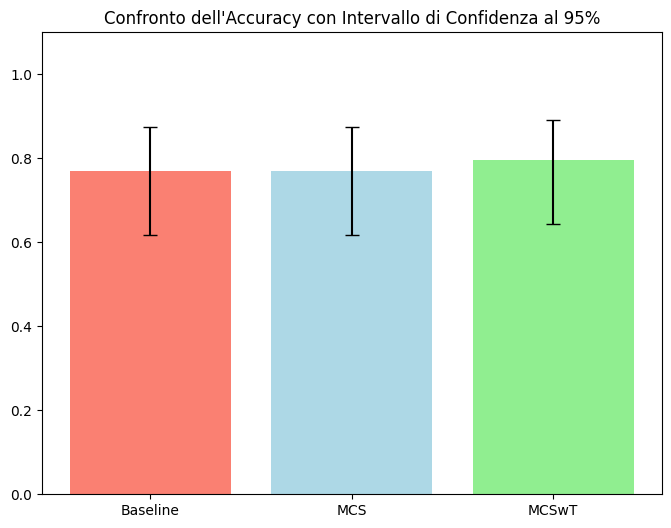

In [24]:
import os
os.makedirs('/content/gdrive/MyDrive/tesi/first-milestone-plots', exist_ok=True)

x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_accuracy, mcs_accuracy, mcswt_accuracy]

lower_errors = [
    baseline_accuracy - baseline_accuracy_confidence_interval[0],
    mcs_accuracy - mcs_accuracy_confidence_interval[0],
    mcswt_accuracy - mcswt_accuracy_confidence_interval[0]
]
upper_errors = [
    baseline_accuracy_confidence_interval[1] - baseline_accuracy,
    mcs_accuracy_confidence_interval[1] - mcs_accuracy,
    mcswt_accuracy_confidence_interval[1] - mcswt_accuracy
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto dell'Accuracy con Intervallo di Confidenza al 95%")
plt.ylim(0, 1.1)
plt.savefig('/content/gdrive/MyDrive/tesi/first-milestone-plots/accuracy_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Macro Averaged Precision
La precision misura quanti, tra i video che il modello ha classificato come appartenenti a una classe, appartengono effettivamente a quella classe.

La Macro Averaged Precision è la media aritmetica della precision della classe del condutente e della precision di quella del passeggero.

Le barre al di sopra delle colonne mostrano la seguente informazione: siamo sicuri al 95% che il valore sia compreso tra il limite inferiore della barra e il limite superiore della barra nell'universo di tutti i possibili video.

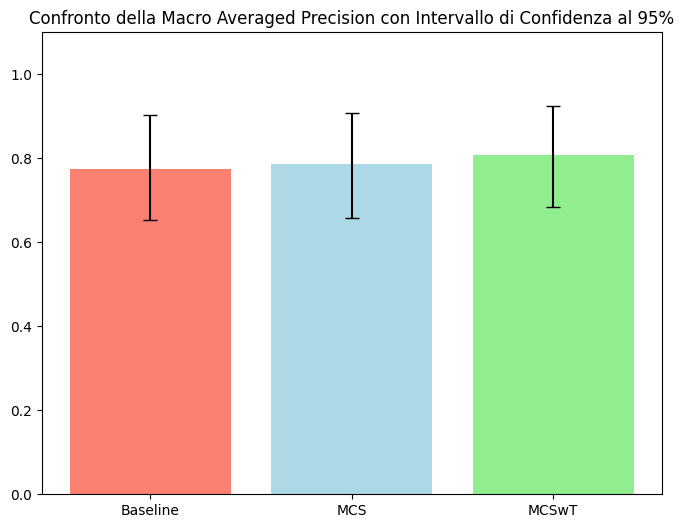

In [25]:
import os
os.makedirs('/content/gdrive/MyDrive/tesi/first-milestone-plots', exist_ok=True)

x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_MAP, mcs_MAP, mcswt_MAP]

lower_errors = [
    baseline_MAP - baseline_MAP_confidence_interval[0],
    mcs_MAP - mcs_MAP_confidence_interval[0],
    mcswt_MAP - mcswt_MAP_confidence_interval[0]
]
upper_errors = [
    baseline_MAP_confidence_interval[1] - baseline_MAP,
    mcs_MAP_confidence_interval[1] - mcs_MAP,
    mcswt_MAP_confidence_interval[1] - mcswt_MAP
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto della Macro Averaged Precision con Intervallo di Confidenza al 95%")
plt.ylim(0, 1.1)
plt.savefig('/content/gdrive/MyDrive/tesi/first-milestone-plots/precision_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Macro Averaged Recall
La recall misura la capacità del modello di trovare tutti i video reali appartenenti a una determinata classe.

La Macro Averaged Recall è la media aritmetica del Recall del conducente e del Recall del passeggero.

Le barre al di sopra delle colonne mostrano la seguente informazione: siamo sicuri al 95% che il valore sia compreso tra il limite inferiore della barra e il limite superiore della barra nell'universo di tutti i possibili video.

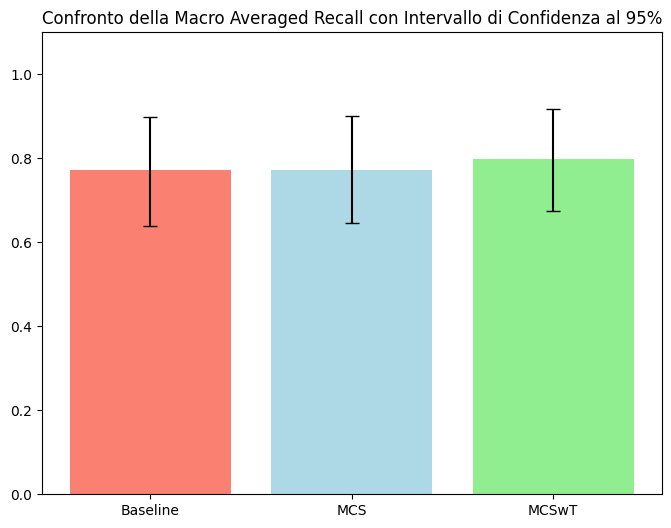

In [26]:
import os
os.makedirs('/content/gdrive/MyDrive/tesi/first-milestone-plots', exist_ok=True)

x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_MAR, mcs_MAR, mcswt_MAR]

lower_errors = [
    baseline_MAR - baseline_MAR_confidence_interval[0],
    mcs_MAR - mcs_MAR_confidence_interval[0],
    mcswt_MAR - mcswt_MAR_confidence_interval[0]
]
upper_errors = [
    baseline_MAR_confidence_interval[1] - baseline_MAR,
    mcs_MAR_confidence_interval[1] - mcs_MAR,
    mcswt_MAR_confidence_interval[1] - mcswt_MAR
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto della Macro Averaged Recall con Intervallo di Confidenza al 95%")
plt.ylim(0, 1.1)
plt.savefig('/content/gdrive/MyDrive/tesi/first-milestone-plots/recall_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Macro Averaged F-Measure
Metrica che integra Precision e Recall.

Le barre al di sopra delle colonne mostrano la seguente informazione: siamo sicuri al 95% che il valore sia compreso tra il limite inferiore della barra e il limite superiore della barra nell'universo di tutti i possibili video.

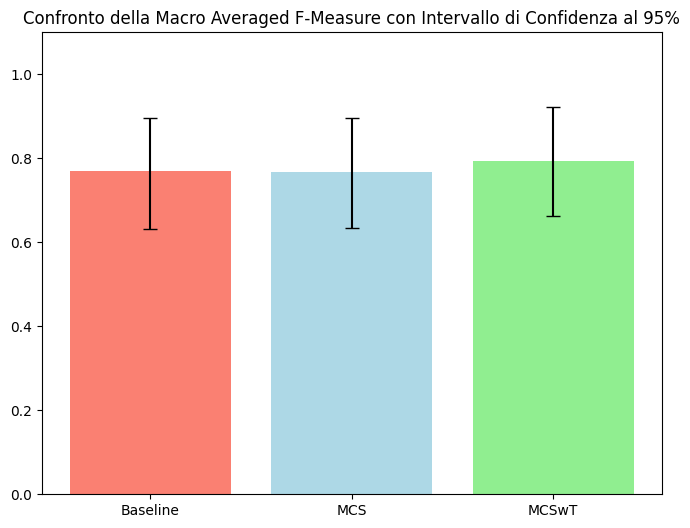

In [27]:
import os
os.makedirs('/content/gdrive/MyDrive/tesi/first-milestone-plots', exist_ok=True)

x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_offset_or_MAF := baseline_MAF, mcs_MAF, mcswt_MAF]

lower_errors = [
    baseline_MAF - baseline_MAF_confidence_interval[0],
    mcs_MAF - mcs_MAF_confidence_interval[0],
    mcswt_MAF - mcswt_MAF_confidence_interval[0]
]
upper_errors = [
    baseline_MAF_confidence_interval[1] - baseline_MAF,
    mcs_MAF_confidence_interval[1] - mcs_MAF,
    mcswt_MAF_confidence_interval[1] - mcswt_MAF
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto della Macro Averaged F-Measure con Intervallo di Confidenza al 95%")
plt.ylim(0, 1.1)
plt.savefig('/content/gdrive/MyDrive/tesi/first-milestone-plots/f_measure_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

## Delay medio
Il delay di uno specifico video è il numero di fotogrammi scansionati per giungere
all'accuratezza del 80% (ovvero, tra tutte le finestre scansionate fino al raggiungimento del delay, l'80% di esse concorda sulla decisione di maggioranza corrente coerentemente con la formula del consenso interno).

Il delay medio è semplicemente la media dei delay di tutti i video.

Le barre al di sopra delle colonne mostrano la seguente informazione: siamo sicuri al 95% che il valore sia compreso tra il limite inferiore della barra e il limite superiore della barra nell'universo di tutti i possibili video.

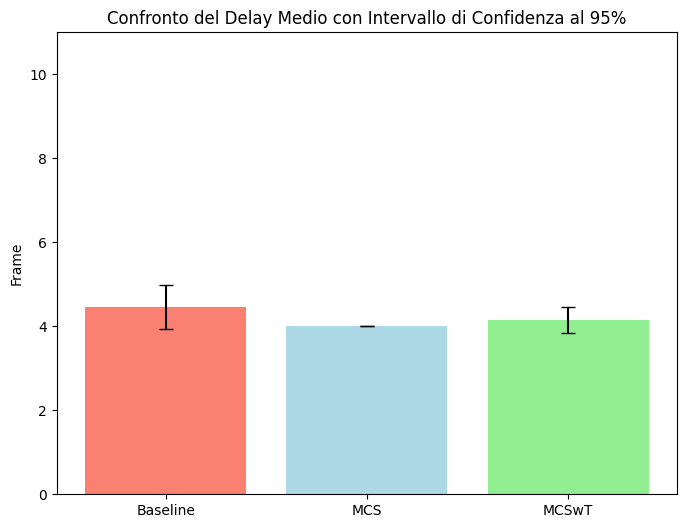

In [28]:
import os
os.makedirs('/content/gdrive/MyDrive/tesi/first-milestone-plots', exist_ok=True)

x_axis_tags = ["Baseline", "MCS", "MCSwT"]
y_axis_tags = [baseline_delay_avg, mcs_delay_avg, mcswt_delay_avg]

lower_errors = [
    baseline_delay_avg - baseline_delay_confidence_interval[0],
    mcs_delay_avg - mcs_delay_confidence_interval[0],
    mcswt_delay_avg - mcswt_delay_confidence_interval[0]
]
upper_errors = [
    baseline_delay_confidence_interval[1] - baseline_delay_avg,
    mcs_delay_confidence_interval[1] - mcs_delay_avg,
    mcswt_delay_confidence_interval[1] - mcswt_delay_avg
]
asymmetric_error = [lower_errors, upper_errors]

plt.figure(figsize=(8, 6))
plt.bar(x=x_axis_tags, height=y_axis_tags, yerr=asymmetric_error, capsize=5, color=['salmon', 'lightblue', 'lightgreen'])
plt.title("Confronto del Delay Medio con Intervallo di Confidenza al 95%")
plt.ylabel("Frame")
plt.ylim(0, 11)
plt.savefig('/content/gdrive/MyDrive/tesi/first-milestone-plots/delay_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

In [29]:
# Eseguiamo il flush e lo smontaggio sicuro del Google Drive alla fine del notebook
drive.flush_and_unmount()
print("Google Drive smontato con successo e in modo sicuro!")

Google Drive smontato con successo e in modo sicuro!
